In [1]:
import pandas as pd

df = pd.read_csv("iris.csv")
print(df.shape)
df.head()

(150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [2]:
print(df.info())
print(df.describe())
print(df["species"].value_counts())
print("Missing values:", df.isna().sum().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    object 
dtypes: float64(4), object(1)
memory usage: 6.0+ KB
None
       sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.054000      3.758667     1.198667
std        0.828066     0.433594      1.764420     0.763161
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.50000

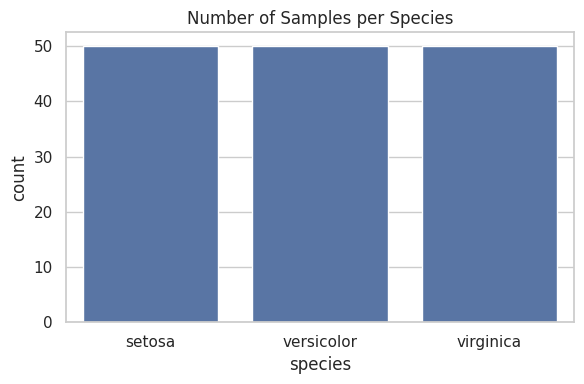

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("images", exist_ok=True)
sns.set_theme(style="whitegrid")

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="species")
plt.title("Number of Samples per Species")
plt.tight_layout()
plt.savefig("images/class_distribution.png", dpi=300)
plt.show()

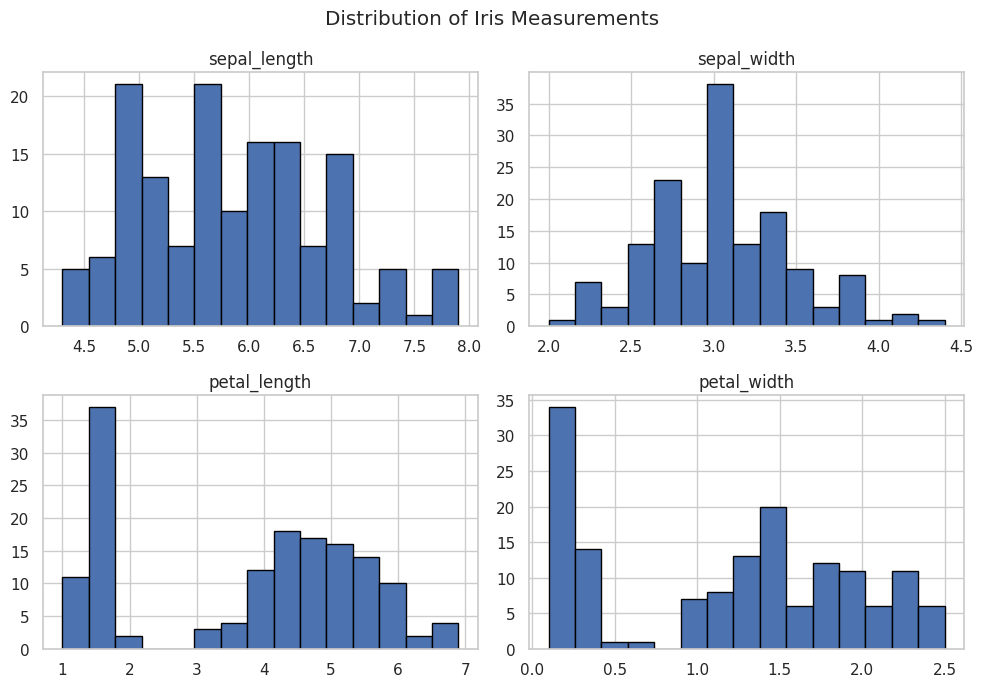

In [4]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]

df[features].hist(figsize=(10, 7), bins=15, edgecolor="black")
plt.suptitle("Distribution of Iris Measurements")
plt.tight_layout()
plt.savefig("images/feature_histograms.png", dpi=300)
plt.show()

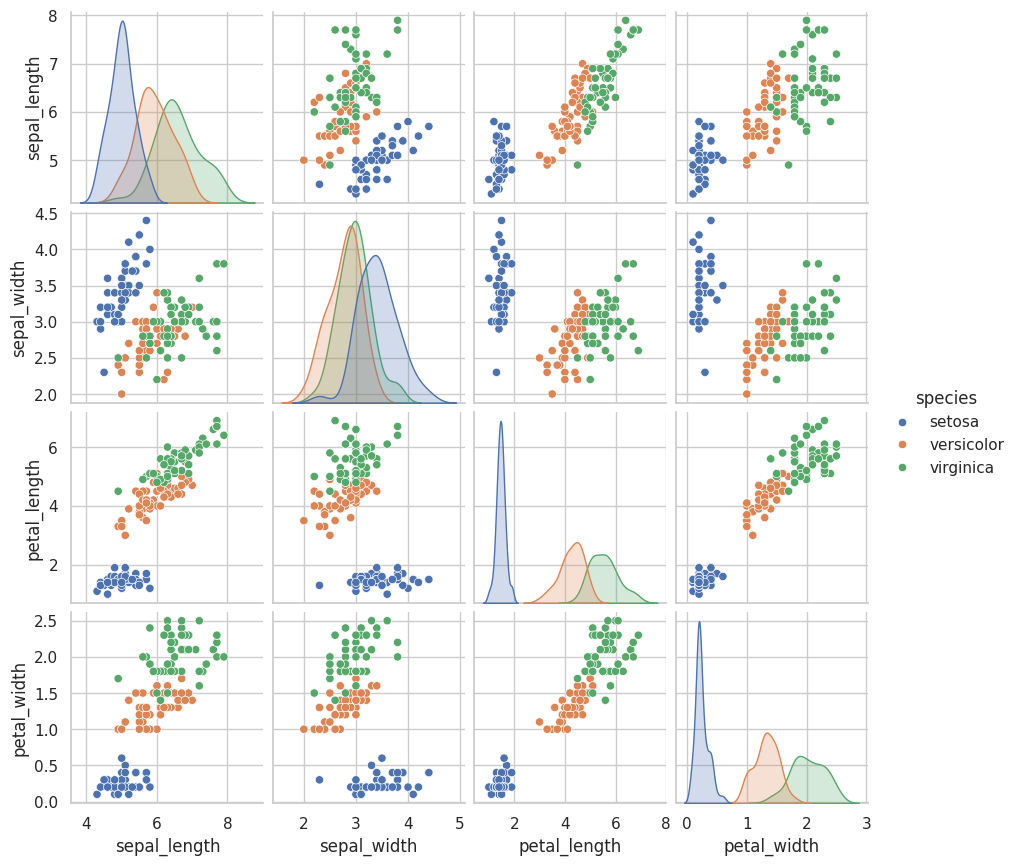

In [5]:
sns.pairplot(df, hue="species", height=2.2)
plt.savefig("images/pairplot.png", dpi=300)
plt.show()

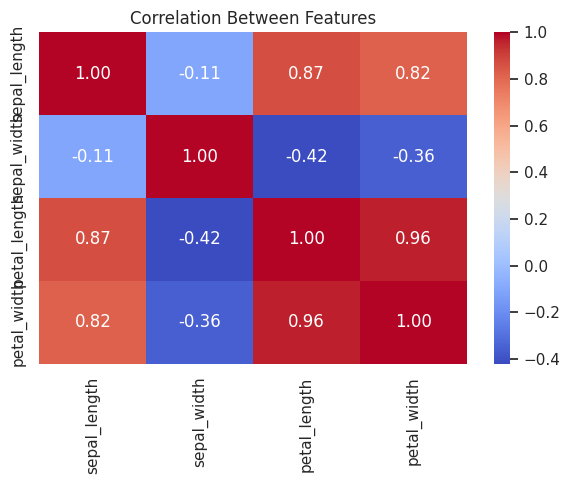

In [6]:
plt.figure(figsize=(6, 5))
sns.heatmap(df[features].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Features")
plt.tight_layout()
plt.savefig("images/correlation_heatmap.png", dpi=300)
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df[features]
y = df["species"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

Training set: (120, 4)
Test set: (30, 4)


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": LogisticRegression(max_iter=500),
    "KNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=42),
}

for name, model in models.items():
    model.fit(X_train_s, y_train)
    pred = model.predict(X_test_s)
    print(f"{name}: {accuracy_score(y_test, pred):.4f}")

Logistic Regression: 0.9333
KNN (k=5): 0.9333
Decision Tree: 0.9667


In [9]:
from sklearn.model_selection import cross_val_score

cv_scores = {
    name: cross_val_score(model, X_train_s, y_train, cv=5).mean()
    for name, model in models.items()
}
for name, score in cv_scores.items():
    print(f"{name}: {score:.4f}")

best_name = max(cv_scores, key=cv_scores.get)
best_model = models[best_name]
print("\nBest model:", best_name)

Logistic Regression: 0.9583
KNN (k=5): 0.9667
Decision Tree: 0.9333

Best model: KNN (k=5)


In [10]:
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score)

y_pred = best_model.predict(X_test_s)

print(classification_report(y_test, y_pred))
print("Accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, average="macro"), 4))
print("Recall   :", round(recall_score(y_test, y_pred, average="macro"), 4))
print("F1 score :", round(f1_score(y_test, y_pred, average="macro"), 4))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.83      1.00      0.91        10
   virginica       1.00      0.80      0.89        10

    accuracy                           0.93        30
   macro avg       0.94      0.93      0.93        30
weighted avg       0.94      0.93      0.93        30

Accuracy : 0.9333
Precision: 0.9444
Recall   : 0.9333
F1 score : 0.9327


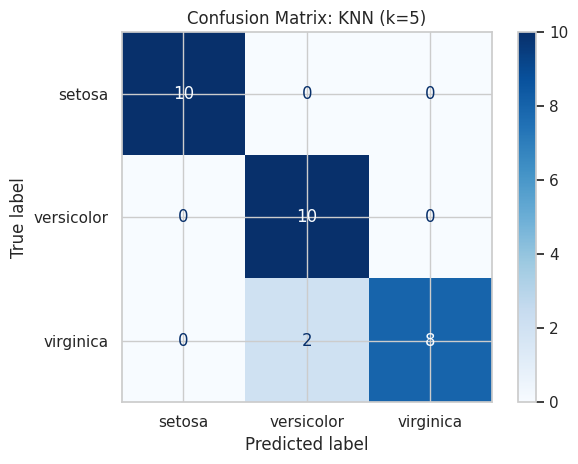

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=best_model.classes_)
disp = ConfusionMatrixDisplay(cm, display_labels=best_model.classes_)
disp.plot(cmap="Blues")
plt.title(f"Confusion Matrix: {best_name}")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=300)
plt.show()

In [12]:
import json

report = classification_report(y_test, y_pred, output_dict=True)

model_data = {
    "model": "KNN",
    "k": 5,
    "features": features,
    "classes": list(best_model.classes_),
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "X_train": X_train_s.tolist(),
    "y_train": y_train.tolist(),
    "metrics": {
        "accuracy": round(accuracy_score(y_test, y_pred), 4),
        "precision": round(precision_score(y_test, y_pred, average="macro"), 4),
        "recall": round(recall_score(y_test, y_pred, average="macro"), 4),
        "f1": round(f1_score(y_test, y_pred, average="macro"), 4),
        "confusion_matrix": cm.tolist(),
        "per_class": report,
    },
}

os.makedirs("model", exist_ok=True)
with open("model/iris_model.json", "w") as f:
    json.dump(model_data, f)

print("Saved. Training rows:", len(model_data["X_train"]))

Saved. Training rows: 120


In [13]:
import shutil
from google.colab import files

shutil.make_archive("images", "zip", "images")
files.download("model/iris_model.json")
files.download("images.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>